# AI Agents and Reinforcement Learning: a Q-learning Agent in a Maze

**The idea in one minute.** Imagine dropping a robot at the corner of a maze and saying only: *"get to the opposite corner."* You do not tell it where the walls are or which way to turn. After every move it gets a score: a small penalty for each step, a big penalty for hitting a wall, a big prize for reaching the exit. At first it blunders around. After thousands of attempts it walks the shortest route. This notebook builds that robot, a small **AI agent that learns by Reinforcement Learning (RL)**, and shows how it improves.

It follows two sources:

- **[1] Google Cloud, "What are AI agents?"**: what an agent is and what it is made of.
- **[2] GeeksforGeeks, "What is Reinforcement Learning?"**: how an agent learns from rewards. The maze and all its settings come from this article.

| Part | Question it answers |
|---|---|
| 1 | What is an AI agent, and where does RL fit in? |
| 2 | What does the maze look like, and how is the agent scored? |
| 3 | How bad is an agent that knows nothing? (the baseline) |
| 4 | How does Q-learning store what the agent learns? |
| 5 | Does the agent improve during training? |
| 6 | What did it actually learn? |
| 7 | Is the trained agent really better than the random one? |
| 8 | What are the limits of this approach? |

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
FIG = ROOT / "report" / "images"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 110

def save(name):
    # every figure is also saved for the report
    plt.savefig(FIG / name, dpi=160, bbox_inches="tight")

## 1. What is an AI agent, and where does reinforcement learning fit?

### An agent has a goal, not a script

A normal program follows instructions: *if this happens, do that*. An **AI agent** is given a **goal** and works out for itself what to do. [1] defines it as *"software systems that use AI to pursue goals and complete tasks on behalf of users"* that can *"make decisions, learn, and adapt"*.

According to [1], an agent does five things, over and over:

| Ability [1] | Plain meaning | The robot in the maze |
|---|---|---|
| **Observing** | look at the situation | check which cell it is standing in |
| **Reasoning / planning** | decide what to do next | choose a direction |
| **Acting** | do something that changes the situation | take one step |
| **Self-refining** | learn from feedback and do better next time | adjust its knowledge using the score |
| **Memory** | remember what it learned | a table of numbers (Part 4) |

[1] also separates three things that are easy to confuse:

- a **bot** follows fixed rules and barely learns;
- an **AI assistant** answers requests, but *the user* decides;
- an **AI agent** is the most independent: it acts toward a goal on its own and learns and adapts.

### Where reinforcement learning comes in

The last ability, *learning from feedback*, is exactly what **reinforcement learning** provides. [2] describes RL as learning *"through trial and error to maximize cumulative reward"*: the agent tries things, gets a reward or a penalty, and gradually keeps what worked.

RL has five key words. Each one matches something in the agent's loop:

| RL word [2] | Meaning | Maze example |
|---|---|---|
| **Environment** | the world the agent lives in | the 10 × 10 grid |
| **State** | the agent's current situation | which cell it is in |
| **Action** | a move it can make | left, right, up or down |
| **Reward** | the score the environment gives after an action | +50, −1 or −10 |
| **Policy** | the agent's rule for picking an action in each state | "in this cell, go right" |

### Why learn by trial and error?

Nobody can write down the correct move for every position of a maze, a chess game or a robot arm. But it is easy to say whether an *outcome* was good or bad: "reached the goal", "crashed", "took too long". RL learns from exactly that kind of signal. The price is that the agent must try many things, most of them bad, before it finds what works.

### The loop

The agent repeats this cycle until it reaches its goal:

```
        ┌─────────── 1. observe the state ◀───────────┐
        ▼                                              │
  2. choose an action (policy)             4. environment answers with
        │                                     a new state and a reward
        └─────────── 3. act ───────────────────────────┘
                              5. learn: update from the reward
```

## 2. The environment: a 10 × 10 maze

The maze follows [2]: a 10 × 10 grid where each cell is a free path (`0`) or an obstacle (`1`). The agent starts at the top-left cell `(0, 0)` and must reach the bottom-right cell `(9, 9)`. From any cell it can try four **actions**: left, right, up, down.

### The scoring (rewards)

Rewards are how we tell the agent what we want without telling it *how* to do it. They also come from [2], and each has a purpose:

| Event | Reward | Why this value |
|---|---|---|
| Reaching the goal | **+50** | the outcome we want, big enough to be worth the walk |
| Every ordinary step | **−1** | a small cost for time. Without it, a long wandering path scores the same as a short one, and the agent would never look for the *shortest* path |
| Walking into an obstacle or off the grid | **−10** | a strong penalty, and the attempt ends |

Two words used below:

- an **episode** is one attempt, from the start cell until the agent reaches the goal, crashes, or runs out of moves (at most 200);
- **training** is many episodes in a row. The agent keeps what it learned from one episode to the next.

The article does not print its exact grid, so the layout below is our own. A standard search (breadth-first search) finds that the shortest route is **22 steps**. We use it only as a yardstick, to check later whether the agent finds the true best route. The agent itself never sees it.

In [2]:
MAZE = np.array([
    [0, 0, 0, 1, 0, 0, 0, 0, 1, 0],
    [1, 1, 0, 1, 0, 1, 1, 0, 1, 0],
    [0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
    [0, 1, 1, 1, 1, 0, 1, 1, 1, 0],
    [0, 0, 0, 0, 1, 0, 0, 0, 1, 0],
    [1, 1, 1, 0, 1, 1, 1, 0, 1, 0],
    [0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
    [0, 1, 1, 1, 1, 0, 1, 1, 1, 1],
    [0, 0, 0, 0, 1, 0, 0, 0, 0, 0],
    [1, 1, 1, 0, 0, 0, 1, 1, 1, 0],
])
START, GOAL = (0, 0), (9, 9)
ACTIONS = {0: (0, -1), 1: (0, 1), 2: (-1, 0), 3: (1, 0)}      # left, right, up, down
ARROWS = {0: "←", 1: "→", 2: "↑", 3: "↓"}
REWARD_GOAL, REWARD_STEP, REWARD_FIRE = 50, -1, -10

def step(state, action):
    # the environment: apply one action, return (new state, reward, episode finished?)
    r, c = state
    dr, dc = ACTIONS[action]
    nr, nc = r + dr, c + dc
    if not (0 <= nr < 10 and 0 <= nc < 10) or MAZE[nr, nc] == 1:
        return state, REWARD_FIRE, True          # crashed: big penalty, attempt over
    if (nr, nc) == GOAL:
        return (nr, nc), REWARD_GOAL, True       # success
    return (nr, nc), REWARD_STEP, False          # an ordinary step

def shortest_path_length():
    # breadth-first search, only to know the true optimum for comparison
    from collections import deque
    seen, q = {START: 0}, deque([START])
    while q:
        s = q.popleft()
        for a in ACTIONS:
            n, _, _ = step(s, a)
            if n != s and n not in seen:
                seen[n] = seen[s] + 1
                q.append(n)
    return seen[GOAL]

print("free cells:", int((MAZE == 0).sum()), " obstacles:", int(MAZE.sum()))
print("shortest possible path:", shortest_path_length(), "steps")

free cells: 59  obstacles: 41
shortest possible path: 22 steps


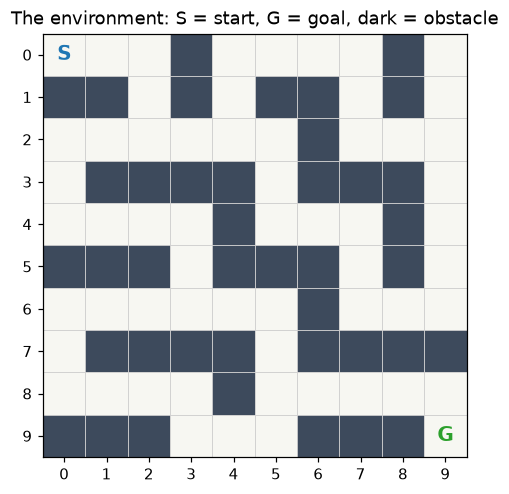

In [3]:
def draw_maze(ax, title=""):
    ax.imshow(MAZE, cmap=ListedColormap(["#f7f7f2", "#3d4a5c"]))
    ax.set_xticks(range(10)); ax.set_yticks(range(10))
    ax.set_xticks(np.arange(-.5, 10), minor=True); ax.set_yticks(np.arange(-.5, 10), minor=True)
    ax.grid(which="minor", color="#cfcfcf", linewidth=0.6); ax.tick_params(which="minor", length=0)
    ax.text(START[1], START[0], "S", ha="center", va="center", fontsize=13, fontweight="bold", color="#1f77b4")
    ax.text(GOAL[1], GOAL[0], "G", ha="center", va="center", fontsize=13, fontweight="bold", color="#2ca02c")
    ax.set_title(title)

fig, ax = plt.subplots(figsize=(5, 5))
draw_maze(ax, "The environment: S = start, G = goal, dark = obstacle")
save("maze.png"); plt.show()

## 3. A baseline: an agent that knows nothing

Before any learning, the only thing the agent can do is pick one of the four moves at random. We run this first for two reasons:

1. it shows how hard the task is without learning;
2. it gives us a fixed starting point. If learning works, the trained agent must be clearly better than this one (Part 7).

In [4]:
rng = np.random.default_rng(0)

def run(policy, start=START, max_steps=200):
    # one episode following `policy(state) -> action`; returns (reached goal?, steps, total reward, path)
    s, total, path = start, 0, [start]
    for t in range(1, max_steps + 1):
        s, r, done = step(s, policy(s))
        total += r
        path.append(s)
        if done:
            return s == GOAL, t, total, path
    return False, max_steps, total, path

random_policy = lambda s: int(rng.integers(4))
results = [run(random_policy) for _ in range(1000)]
print(f"random agent: reached the goal in {sum(r[0] for r in results)} of 1000 attempts")
print(f"average attempt length before crashing: {np.mean([r[1] for r in results]):.1f} moves")

random agent: reached the goal in 0 of 1000 attempts
average attempt length before crashing: 1.5 moves


**Result:** the random agent never reaches the goal. After about one or two moves it walks into a wall or off the grid, and the attempt is over. This is the situation the learning agent starts from: its first episodes look exactly like this.

## 4. Q-learning: how the agent remembers and improves

### The Q-table: a cheat sheet that fills itself in

To act well, the agent needs to know, for every cell and every move, **how good that move is**, counting not only the next step but everything that follows. Moving right from the start may cost −1 now, yet be a great move because it leads toward the goal. Moving down from the start crashes into a wall and is terrible.

**Q-learning** keeps these judgements in a table, the **Q-table**. It has one row per cell (100 rows) and one column per action (4 columns). Each number, a **Q-value**, answers: *"if I make this move from this cell and then keep playing well, how much total reward can I expect?"*

- The table starts full of zeros: at first the agent knows nothing.
- It is the agent's **memory** in the sense of [1].
- Once it is good, the **policy** is easy: *in each cell, take the move with the highest number.*

### Exploration vs. exploitation: try new things or use what you know?

Think of choosing a restaurant. If you always return to the first place you tried, you may never find a better one. If you always try somewhere new, you never enjoy the best place you already found. The agent faces the same trade-off, which [2] calls **exploration** (trying new actions) versus **exploitation** (using known good actions).

The standard answer, used in [2], is **ε-greedy** ("epsilon-greedy"). With probability ε the agent makes a random move; otherwise it takes its best known move. ε starts at 0.5 (half of all moves are experiments) and is multiplied by 0.995 after every episode, never going below 0.01. So the agent explores a lot while it knows little, and relies on its table more as the table becomes reliable.

### The learning step: compare what you expected with what you got

After every move the agent asks itself two questions:

- **What did I *expect* this move to be worth?** That is the current Q-value.
- **What do I *now believe* it is worth?** That is the reward it just got, plus the value of the best move available from the cell it landed in, counted at 90% (the **discount factor** γ = 0.9, because a reward that comes later is a little less certain than one received now).

The gap between the two is the agent's **surprise**. The agent moves its Q-value 10% of the way toward the new belief (the **learning rate** α = 0.1). It takes only a small step because one experience may be a fluke; many small steps average out the luck.

In symbols, the update rule of [2] is `Q(s,a) ← Q(s,a) + α [ r + γ · max Q(s′,a′) − Q(s,a) ]`, which says the same thing. If the move crashed or reached the goal, there is no next cell to look ahead to, so the new belief is just the reward itself.

The code below defines this rule and applies it once to a toy table, so you can follow real numbers.

In [5]:
ALPHA, GAMMA = 0.1, 0.9
EPS_START, EPS_DECAY, EPS_MIN = 0.5, 0.995, 0.01
EPISODES = 5000

def update(Q, s, a, r, s_next, done):
    expected = Q[s][a]
    believed = r if done else r + GAMMA * Q[s_next].max()
    Q[s][a] = expected + ALPHA * (believed - expected)
    return expected, believed

# one worked step on real numbers, on a toy table
Q_demo = np.zeros((10, 10, 4))
Q_demo[(0, 2)] = [-1.0, 3.0, 0.0, 6.0]             # pretend the agent already values cell (0,2) a little
s, a = (0, 1), 1                                    # in cell (0,1), move right
s_next, r, done = step(s, a)
expected, believed = update(Q_demo, s, a, r, s_next, done)
print(f"move right from (0,1) -> landed in {s_next}, reward {r}")
print(f"expected value of the move : {expected:.2f}")
print(f"new belief: reward {r} + 0.9 x best value at {s_next} ({Q_demo[s_next].max():.1f}) = {believed:.2f}")
print(f"surprise = {believed - expected:.2f}; move 10% of the way -> new Q-value {Q_demo[s][a]:.2f}")

move right from (0,1) -> landed in (0, 2), reward -1
expected value of the move : 0.00
new belief: reward -1 + 0.9 x best value at (0, 2) (6.0) = 4.40
surprise = 4.40; move 10% of the way -> new Q-value 0.44


**Reading the example.** The agent expected nothing (0) from moving right. It received −1, but it landed in a cell whose best move it already values at 6, so its new belief is −1 + 0.9 × 6 = 4.4. The value of this move rises from 0 to 0.44.

Repeated over thousands of moves, this is how the value of the goal **spreads backward through the maze**: first the cells next to the goal become valuable, then the cells next to those, and so on, all the way back to the start.

## 5. Training

Training is the loop from Part 1 repeated for 5,000 episodes. In each step the agent observes its cell, picks a move with ε-greedy, acts, receives the reward and the new cell, and updates the Q-table. For every episode we record the total reward, the number of moves, and whether the goal was reached, so we can watch the agent improve.

In [6]:
rng = np.random.default_rng(42)
Q = np.zeros((10, 10, 4))
eps = EPS_START
log = {"reward": [], "steps": [], "success": [], "eps": []}

def eps_greedy(s, eps):
    if rng.random() < eps:
        return int(rng.integers(4))            # explore
    return int(np.argmax(Q[s]))                 # exploit

for ep in range(EPISODES):
    s, total, done, t = START, 0, False, 0
    while not done and t < 200:
        a = eps_greedy(s, eps)
        s_next, r, done = step(s, a)
        update(Q, s, a, r, s_next, done)
        s, total, t = s_next, total + r, t + 1
    log["reward"].append(total); log["steps"].append(t)
    log["success"].append(s == GOAL); log["eps"].append(eps)
    eps = max(EPS_MIN, eps * EPS_DECAY)

succ = np.array(log["success"])
first = int(np.argmax(succ)) + 1
print(f"first time the goal was reached: episode {first}")
print(f"success rate, first 500 episodes: {succ[:500].mean():.0%}   last 500 episodes: {succ[-500:].mean():.0%}")
print(f"average reward, last 500 episodes: {np.mean(log['reward'][-500:]):.1f}")

first time the goal was reached: episode 721
success rate, first 500 episodes: 0%   last 500 episodes: 89%
average reward, last 500 episodes: 23.4


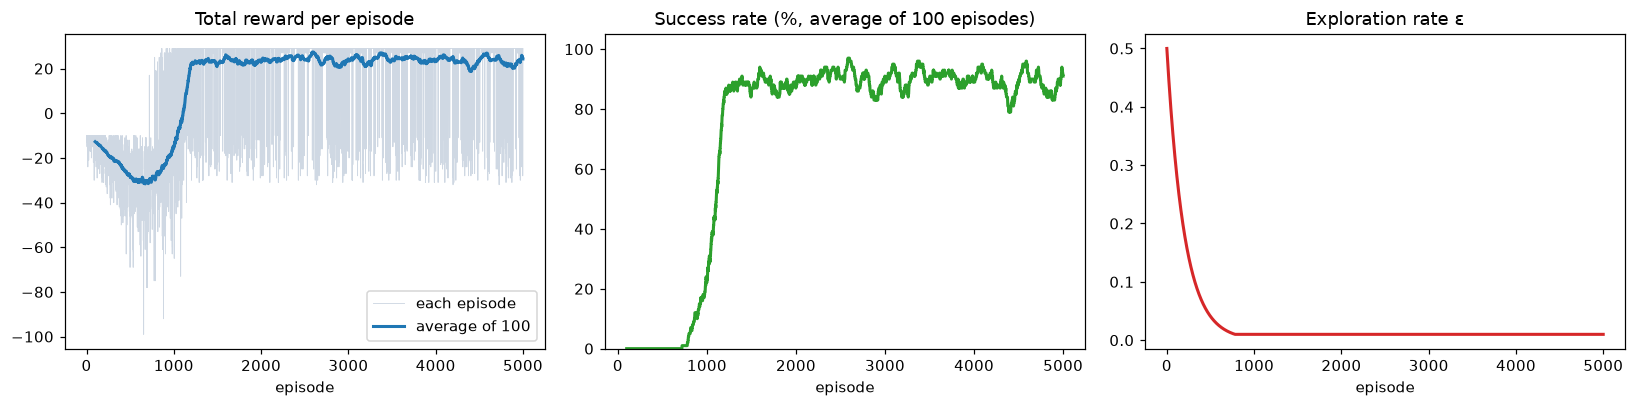

In [7]:
def smooth(x, w=100):
    return np.convolve(x, np.ones(w) / w, mode="valid")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(log["reward"], color="#cfd8e3", lw=0.6, label="each episode")
ax[0].plot(range(99, EPISODES), smooth(log["reward"]), color="#1f77b4", lw=2, label="average of 100")
ax[0].set_title("Total reward per episode"); ax[0].set_xlabel("episode"); ax[0].legend()
ax[1].plot(range(99, EPISODES), smooth(np.array(log["success"], float)) * 100, color="#2ca02c", lw=2)
ax[1].set_title("Success rate (%, average of 100 episodes)"); ax[1].set_xlabel("episode"); ax[1].set_ylim(0, 105)
ax[2].plot(log["eps"], color="#d62728", lw=2)
ax[2].set_title("Exploration rate ε"); ax[2].set_xlabel("episode")
plt.tight_layout(); save("training_curves.png"); plt.show()

### Reading the curves

- **Total reward (left).** For the first 720 episodes the agent never reaches the goal, and the average reward first *falls* (from about −10 to about −30) before it rises. This looks odd, but it makes sense: the agent learns the *first* lesson before the second.
  1. At first it crashes after one or two moves (−10).
  2. Soon it learns that walls hurt and avoids them. But it does not yet know where the exit is, so it wanders safely along the corridors, paying −1 per move until the 200-move limit. A longer attempt means a lower total.
  3. Only when the value of the goal has spread back to the start does the curve turn upward.

  The first success is in episode 721. The best possible total is +29: the +50 prize minus one point for each of the 21 ordinary steps before the last move. The grey line keeps dipping late in training: those are episodes where a random exploratory move sent the agent into a wall.
- **Success rate (middle).** It rises from 0% to about 90% (89% over the last 500 episodes). It stays below 100% because the agent still explores a little, and a random move next to a wall ends the attempt.
- **Exploration rate (right).** ε falls from 0.5 to its floor of 0.01 after about 780 episodes (0.5 × 0.995ⁿ = 0.01). Success starts at about the same time: as the agent trusts its table more, it explores less and crashes less.

## 6. What the agent learned

### The path

To see what the agent learned, we let it play **greedily**: always the best move in its Q-table, no random exploration. We start it at S and draw the cells it visits.

greedy agent: reached goal = True, steps = 22, total reward = 29 (shortest possible: 22 steps)


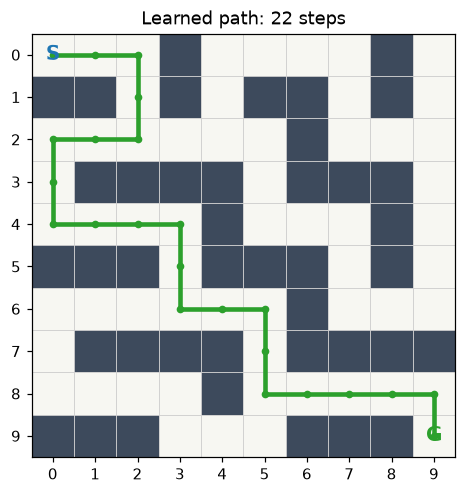

In [8]:
greedy = lambda s: int(np.argmax(Q[s]))
ok, n_steps, total, path = run(greedy)
print(f"greedy agent: reached goal = {ok}, steps = {n_steps}, total reward = {total} "
      f"(shortest possible: {shortest_path_length()} steps)")

fig, ax = plt.subplots(figsize=(5, 5))
draw_maze(ax, f"Learned path: {n_steps} steps")
ys, xs = zip(*path)
ax.plot(xs, ys, color="#2ca02c", lw=3, marker="o", ms=4)
save("learned_path.png"); plt.show()

The trained agent walks straight from S to G in the shortest possible number of steps. Nobody told it where the corridors are: it found the route from rewards alone, and the −1 per step is what made it prefer the *shortest* one.

### The policy: the best move in every cell

The path shows one route only. The Q-table holds a decision for **every** free cell. The picture below draws the best move in each cell as an arrow (this is the **policy**) and uses colour for how valuable the agent thinks the cell is (the highest Q-value in that cell).

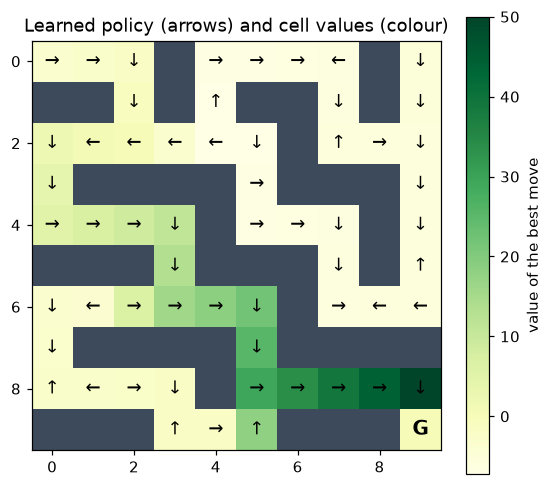

In [9]:
V = Q.max(axis=2)
fig, ax = plt.subplots(figsize=(6, 5.4))
shown = np.where(MAZE == 1, np.nan, V)
im = ax.imshow(shown, cmap="YlGn")
ax.imshow(np.where(MAZE == 1, 1, np.nan), cmap=ListedColormap(["#3d4a5c"]))
for r in range(10):
    for c in range(10):
        if MAZE[r, c] == 0 and (r, c) != GOAL:
            ax.text(c, r, ARROWS[int(np.argmax(Q[r, c]))], ha="center", va="center", fontsize=12)
ax.text(GOAL[1], GOAL[0], "G", ha="center", va="center", fontsize=13, fontweight="bold")
plt.colorbar(im, ax=ax, label="value of the best move")
ax.set_title("Learned policy (arrows) and cell values (colour)")
save("policy.png"); plt.show()

Three things to notice:

1. **Values grow toward the goal.** A cell near G is worth more than a distant one, because fewer step penalties remain and the +50 prize is discounted less.
2. **Cells off the main route are poorly learned.** In the top row, the arrows of cells (0, 6) and (0, 7) point at each other, so an agent placed there would walk back and forth forever. The agent always started at S, so it gained experience mainly along the routes it used from there. Part 7 measures how far this goes.
3. **G itself looks pale.** The attempt ends at G, so no move is ever made *from* it. The value belongs to the move *into* G, which is why its neighbour (8, 9), with its arrow pointing down, is the darkest cell.

## 7. Random agent vs. trained agent

A fair test runs each agent many times. The trained agent behaves the same way every time from S, so we add a harder test: start it from **every free cell** of the maze. If it has really learned the maze, it should reach the goal from anywhere, not only from where it practised.

In [10]:
rng = np.random.default_rng(1)
free = [(r, c) for r in range(10) for c in range(10) if MAZE[r, c] == 0 and (r, c) != GOAL]

rand = [run(random_policy) for _ in range(100)]
trained = [run(greedy) for _ in range(100)]
everywhere = [run(greedy, start=s) for s in free]

# why does the trained agent fail from some cells? (an attempt is cut off after 200 moves)
looped = [s for s, r in zip(free, everywhere) if not r[0] and r[1] == 200]
crashed = [s for s, r in zip(free, everywhere) if not r[0] and r[1] < 200]

rows = [("Random agent, from S (100 runs)", rand),
        ("Trained agent, from S (100 runs)", trained),
        (f"Trained agent, from every free cell ({len(free)} starts)", everywhere)]
print(f"{'':52s}{'success':>8s}{'avg steps':>11s}{'avg reward':>12s}")
for name, res in rows:
    ok = [r for r in res if r[0]]
    steps = np.mean([r[1] for r in ok]) if ok else float('nan')
    print(f"{name:52s}{len(ok)/len(res):>8.0%}{steps:>11.1f}{np.mean([r[2] for r in res]):>12.1f}")
print(f"\nfrom the {len(free)} free cells, the trained agent reaches the goal from {sum(r[0] for r in everywhere)}, "
      f"goes back and forth for all 200 moves from {len(looped)}, and walks into a wall from {len(crashed)}")

                                                     success  avg steps  avg reward
Random agent, from S (100 runs)                           0%        nan       -10.6
Trained agent, from S (100 runs)                        100%       22.0        29.0
Trained agent, from every free cell (58 starts)          47%       11.7       -82.1

from the 58 free cells, the trained agent reaches the goal from 27, goes back and forth for all 200 moves from 29, and walks into a wall from 2


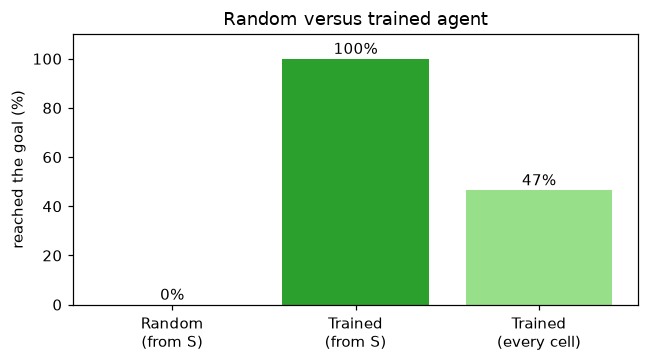

In [11]:
fig, ax = plt.subplots(figsize=(6, 3.4))
labels = ["Random\n(from S)", "Trained\n(from S)", "Trained\n(every cell)"]
vals = [np.mean([r[0] for r in res]) * 100 for _, res in rows]
bars = ax.bar(labels, vals, color=["#c7c7c7", "#2ca02c", "#98df8a"])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 2, f"{v:.0f}%", ha="center")
ax.set_ylim(0, 110); ax.set_ylabel("reached the goal (%)"); ax.set_title("Random versus trained agent")
plt.tight_layout(); save("comparison.png"); plt.show()

### What the numbers say

**From the start cell, learning clearly works.** Same maze, same four moves, same rules: the random agent never reaches the goal, while the agent that learned from 5,000 attempts reaches it every time, along the shortest route of 22 steps.

**From other cells, the picture is much weaker.** The trained agent reaches the goal from only 27 of 58 cells (47%). In almost every other case it does not crash; it **loops**, moving back and forth between two cells until the 200-move limit. That is why the average reward of that row is so low (about −82, roughly −1 per wasted move).

**Why?** During training the agent always started at S, so it only gathered experience along the routes it used from there. In a cell far from those routes, its Q-values come from a few bad experiences, and two neighbouring cells can each rate "go to the other one" as best. Nothing in the reward ever corrected this, because the agent never began there.

This is not a bug in the code but a property of learning from experience: **the agent is only as good as the situations it has practised.** It also shows why testing a learner only under its training conditions (the first two rows) can be misleading. A simple fix would be to start training episodes from random cells so that every part of the maze is experienced.

## 8. Limitations

The maze is small on purpose, so every part of the agent can be seen. Even so, it shows in miniature the limits that both sources describe.

| Limitation | What we saw here |
|---|---|
| **Reward design decides behaviour** [2] | The −1 per step is what makes the agent seek the *shortest* path. A badly chosen reward would make it learn the wrong thing, very efficiently. |
| **Exploration must be balanced** [2] | Too little and the agent sticks with its first route; too much and it keeps crashing. The ε schedule is chosen by us, not learned. |
| **Learning is expensive** [2] | The agent failed 720 times before its first success and needed 5,000 episodes to become reliable, in a tiny 10 × 10 grid. A table with one row per state cannot handle a real robot or game, which have far too many states. Larger systems replace the table with a neural network. |
| **It only knows what it has experienced** | Started anywhere but S, it reaches the goal only about half the time (Part 7). |
| **Trial and error is risky** [1] | [1] lists costly development and high-stakes or unpredictable settings (such as surgery) among the challenges of agents. Crashing hundreds of times is fine in a simulated maze, not on a real road. |

## Summary

| Agent ability [1] | In this notebook |
|---|---|
| Observing | the agent knows its current cell (the state) |
| Reasoning / planning | ε-greedy choice over the Q-table (the policy) |
| Acting | one of four moves |
| Memory | the Q-table, kept between episodes |
| Self-refining | the Q-learning update after every move, driven by the reward |

**In short:** the agent went from never reaching the goal to reaching it every time along the shortest route, using nothing but rewards. That is the core idea of reinforcement learning, and why RL is one of the main ways an AI agent can learn and adapt by itself.